Four tones from one 48-hour cycle, sped up so that cycle repeats at 440 Hz.

The waveform is built on the same grid as the data pipeline: 2048 samples across 48 hours. Harmonic *k* is *k* cycles in that window (periods 48 h, 24 h, 16 h, 12 h). Playback scans the table once per cycle at 440 Hz, the same way the synth plays a wavetable. Each tone below keeps a single harmonic, so after the speed-up it is a sinusoid at *k* × 440 Hz and still repeats every 1/440 s.

In [17]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import rfft, rfftfreq
from scipy.io.wavfile import write

In [26]:
# Same grid as the data pipeline: 2048 samples across one 48 h window.
N_TABLE = 2048
HOURS = 48.0
t_hours = np.linspace(0, HOURS, N_TABLE, endpoint=False)
f0_per_hour = 1.0 / HOURS  # 1st harmonic: one cycle per 48 h

def cycle_table(recipe):
    """Sum harmonics of the 48 h cycle. recipe maps harmonic number -> amplitude."""
    wave = np.zeros(N_TABLE)
    for k, amp in recipe.items():
        wave += amp * np.sin(2 * np.pi * k * f0_per_hour * t_hours)
    return wave

# Exclusive harmonics. A pure k-th harmonic still repeats once per 48 h cycle.
recipes = [
    {1: 1.0},
    {2: 1.0},
    {3: 1.0},
    {4: 1.0},
    {1: 0.2,
     2: 0.8},
    {1: 0.2,
     3: 0.8},
    {1: 0.2,
     4: 0.8},
    {1: 0.35,
     3: 0.65}
]
tables = [cycle_table(recipe) for recipe in recipes]

In [27]:
# Speed the 48 h table up to 440 Hz, matching wavetable playback:
# phase increment = freq * table_size / sample_rate, linear interpolation.
SAMPLE_RATE = 44100
F_CYCLE = 440.0
DURATION = 3.0
FADE_SEC = 0.01

n_audio = int(round(SAMPLE_RATE * DURATION))
phase = (np.arange(n_audio) * (F_CYCLE * N_TABLE / SAMPLE_RATE)) % N_TABLE
i0 = np.floor(phase).astype(np.int64) % N_TABLE
frac = phase - np.floor(phase)
i1 = (i0 + 1) % N_TABLE

fade = np.ones(n_audio)
n_fade = int(SAMPLE_RATE * FADE_SEC)
ramp = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, n_fade, endpoint=False))
fade[:n_fade] *= ramp
fade[-n_fade:] *= ramp[::-1]

def render(table):
    audio = (table[i0] * (1.0 - frac) + table[i1] * frac) * fade
    peak = np.max(np.abs(audio))
    if peak == 0:
        raise ValueError("waveform is silent")
    audio *= 0.9 / peak
    pcm = np.clip(np.rint(audio * 32767.0), -32768, 32767).astype(np.int16)
    return audio, pcm

rendered = [render(table) for table in tables]

IndexError: index 4 is out of bounds for axis 0 with size 4

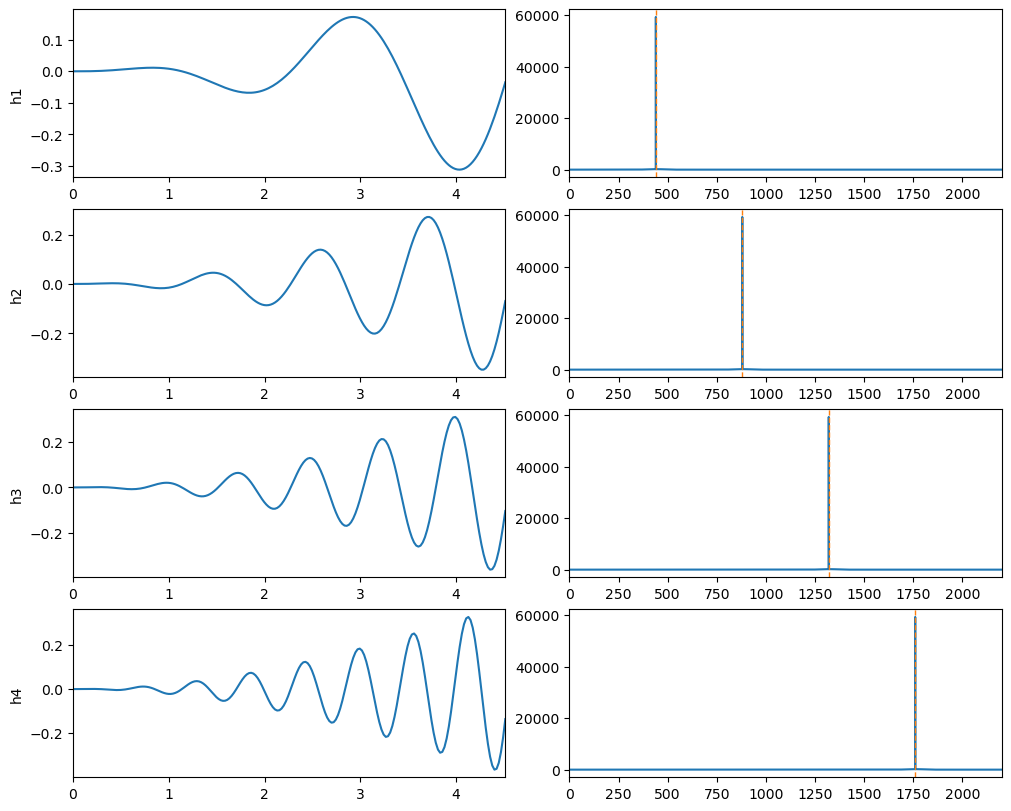

In [24]:
fig, axes = plt.subplots(4, 2, figsize=(10, 8), constrained_layout=True)
n_show = int(SAMPLE_RATE * 2 / F_CYCLE)  # two repetitions of the sped-up 48 h cycle
t_ms = np.arange(n_show) / SAMPLE_RATE * 1000

for k, (audio, _) in enumerate(rendered, start=1):
    axes[k - 1, 0].plot(t_ms, audio[:n_show])
    axes[k - 1, 0].set_ylabel(f"h{k}")
    axes[k - 1, 0].set_xlim(0, t_ms[-1])

    spec = np.abs(rfft(audio))
    freqs = rfftfreq(len(audio), d=1.0 / SAMPLE_RATE)
    axes[k - 1, 1].plot(freqs, spec)
    axes[k - 1, 1].set_xlim(0, 5 * F_CYCLE)
    axes[k - 1, 1].axvline(k * F_CYCLE, color="C1", ls="--", lw=1)

axes[-1, 0].set_xlabel("Time (ms)")
axes[-1, 1].set_xlabel("Frequency (Hz)")
axes[0, 0].set_title("Two cycles at 440 Hz")
axes[0, 1].set_title("Spectrum")
plt.show()

In [28]:
out_dir = Path.cwd()
for k, (_, pcm) in enumerate(rendered, start=1):
    path = out_dir / f"harmonic_{k}_48h_at_440Hz.wav"
    write(path, SAMPLE_RATE, pcm)
    print(f"{path.name}: {len(pcm) / SAMPLE_RATE:.2f}s, peak harmonic {k * F_CYCLE:.0f} Hz")

harmonic_1_48h_at_440Hz.wav: 3.00s, peak harmonic 440 Hz
harmonic_2_48h_at_440Hz.wav: 3.00s, peak harmonic 880 Hz
harmonic_3_48h_at_440Hz.wav: 3.00s, peak harmonic 1320 Hz
harmonic_4_48h_at_440Hz.wav: 3.00s, peak harmonic 1760 Hz
harmonic_5_48h_at_440Hz.wav: 3.00s, peak harmonic 2200 Hz
harmonic_6_48h_at_440Hz.wav: 3.00s, peak harmonic 2640 Hz
harmonic_7_48h_at_440Hz.wav: 3.00s, peak harmonic 3080 Hz
harmonic_8_48h_at_440Hz.wav: 3.00s, peak harmonic 3520 Hz
